# **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

file_path = '/content/drive/MyDrive/Colab&Telco_customer_churn/telco_customer_churn.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully from Google Drive.")

print("\nEmpty or whitespace rows in object-type columns:")
object_columns = df.select_dtypes(include='object').columns
empty_counts = {}
for col in object_columns:
    empty_count = (df[col].str.strip() == '').sum()
    if empty_count > 0:
        empty_counts[col] = empty_count

if empty_counts:
    for col, count in empty_counts.items():
        print(f"Column '{col}' has {count} empty or whitespace rows")
else:
    print("No empty or whitespace rows found in any object-type column")

Mounted at /content/drive
Dataset loaded successfully from Google Drive.

Empty or whitespace rows in object-type columns:
Column 'TotalCharges' has 11 empty or whitespace rows


# **Dataset description**

Number of features: 19
Number of data points: 7043
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


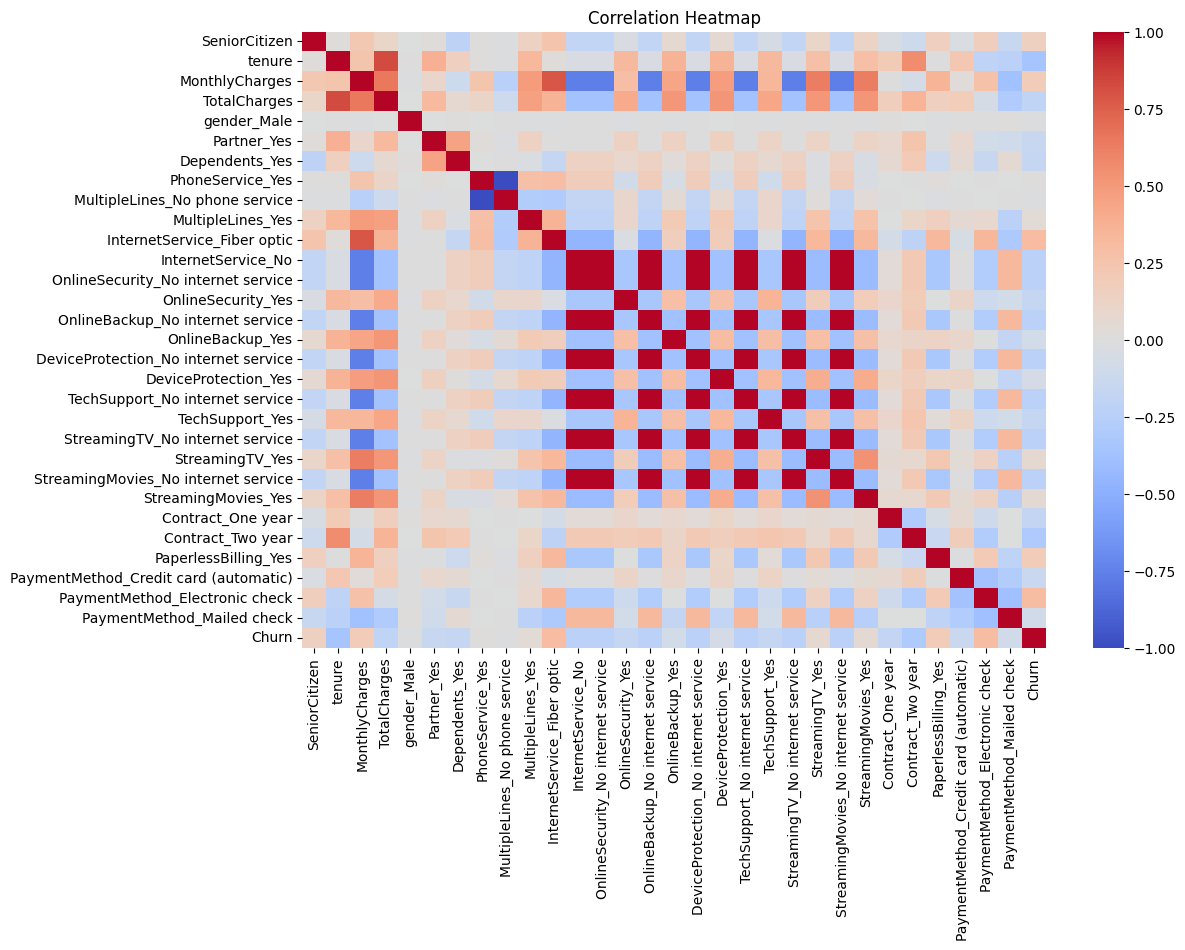

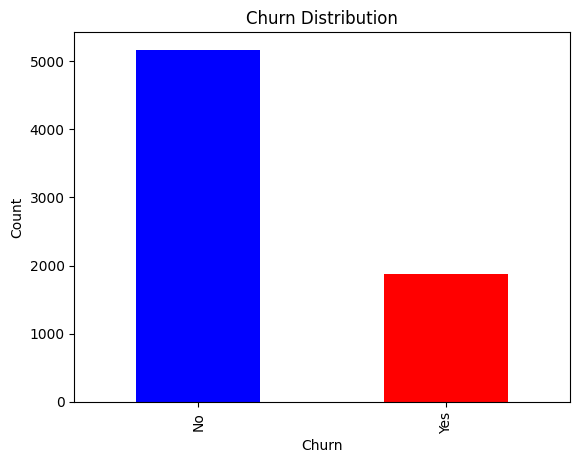

In [ ]:
num_features = len(df.columns) - 2
print(f"Number of features: {num_features}")

num_rows = len(df)
print(f"Number of data points: {num_rows}")


numerical = []
categorical = []
for col in df.columns:
    if col in ['customerID', 'Churn']:
        continue
    if df[col].dtype in ['int64', 'float64'] or col == 'TotalCharges':
              numerical.append(col)
    else:
        categorical.append(col)

print("Numerical features:", numerical)
print("Categorical features:", categorical)


import seaborn as sns
import matplotlib.pyplot as plt

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


df_encoded = pd.get_dummies(df.drop('customerID', axis=1), drop_first=True)
df_encoded['Churn'] = df_encoded['Churn_Yes']
df_encoded.drop(['Churn_Yes', 'Churn_No'], axis=1, inplace=True, errors='ignore')

corr = df_encoded.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.savefig('correlation_heatmap.png')
plt.show()


df['Churn'].value_counts().plot(kind='bar', color=['blue', 'red'])
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()




In [ ]:
numerical_data = df.select_dtypes(include='number')

categorical_data = df.select_dtypes(include='object').drop(columns=['customerID', 'Churn'])


print("Numerical Features Stats:\n", numerical_data.describe().T)
print("\nCategorical Features Stats:\n", categorical_data.describe().T)
print("\nNumerical Features Variance:\n", numerical_data.var())
print("\nNumerical Features Skewness:\n", numerical_data.skew())

Numerical Features Stats:
                  count         mean          std    min      25%       50%  \
SeniorCitizen   7043.0     0.162147     0.368612   0.00    0.000     0.000   
tenure          7043.0    32.371149    24.559481   0.00    9.000    29.000   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.500    70.350   
TotalCharges    7043.0  2281.916928  2265.270398  18.80  402.225  1397.475   

                    75%      max  
SeniorCitizen      0.00     1.00  
tenure            55.00    72.00  
MonthlyCharges    89.85   118.75  
TotalCharges    3786.60  8684.80  

Categorical Features Stats:
                  count unique               top  freq
gender            7043      2              Male  3555
Partner           7043      2                No  3641
Dependents        7043      2                No  4933
PhoneService      7043      2               Yes  6361
MultipleLines     7043      3                No  3390
InternetService   7043      3       Fiber optic  3096

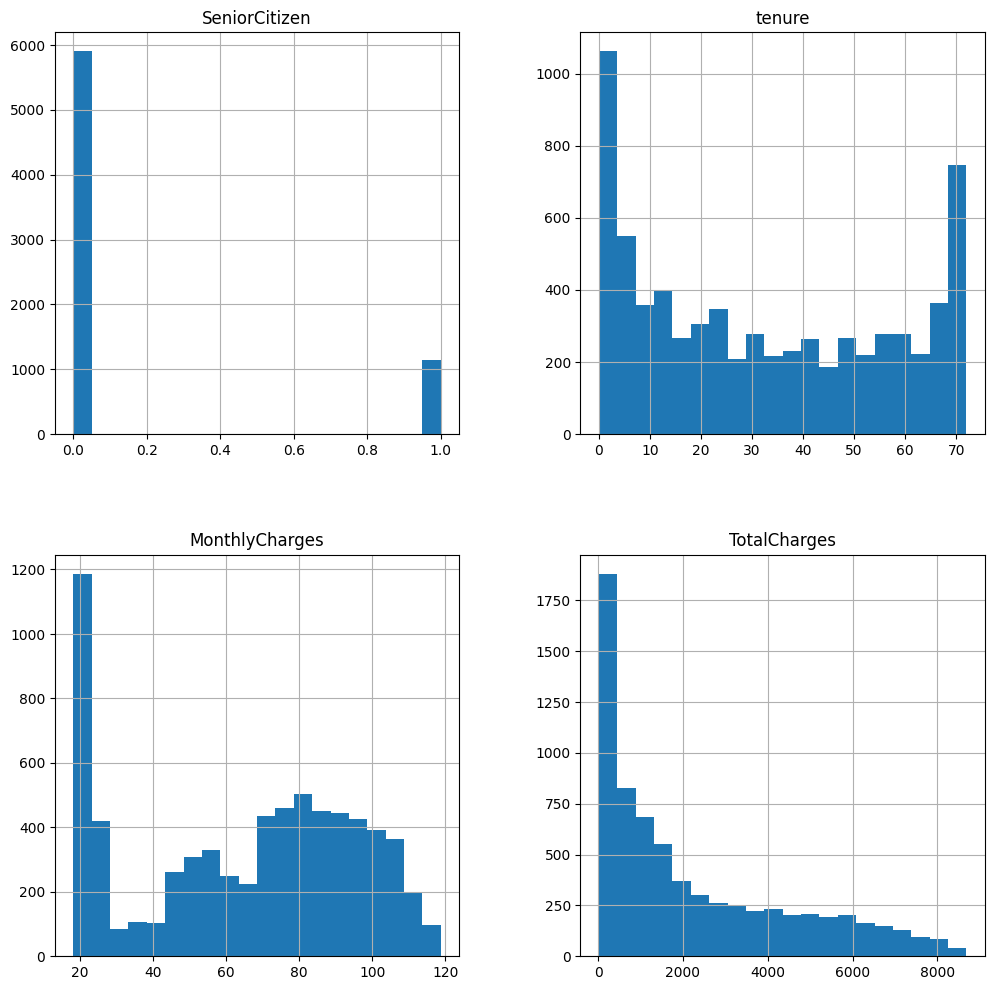

In [ ]:
# Histograms for numerical features
numerical_data.hist(figsize=(12, 12), bins=20)
plt.savefig('numerical_histograms.png')
plt.show()

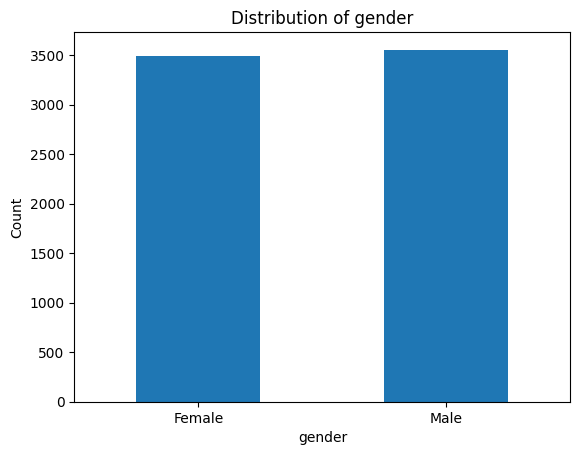

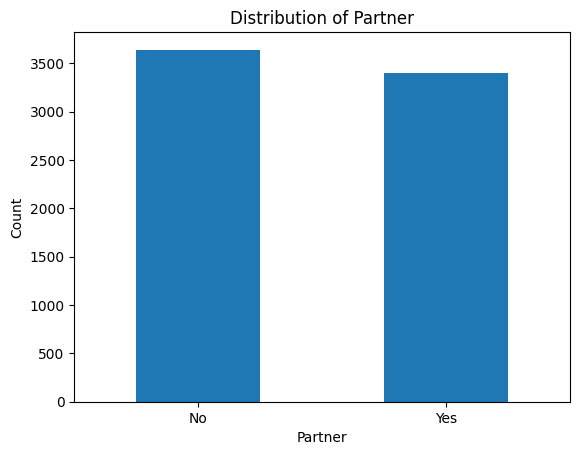

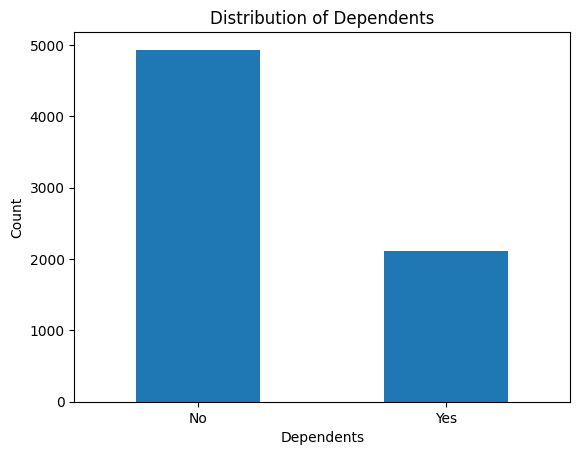

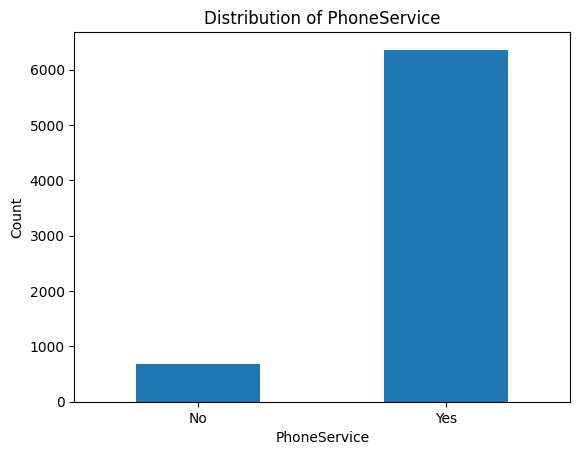

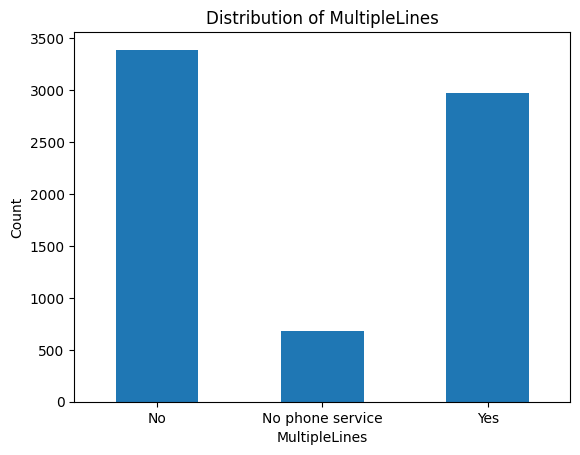

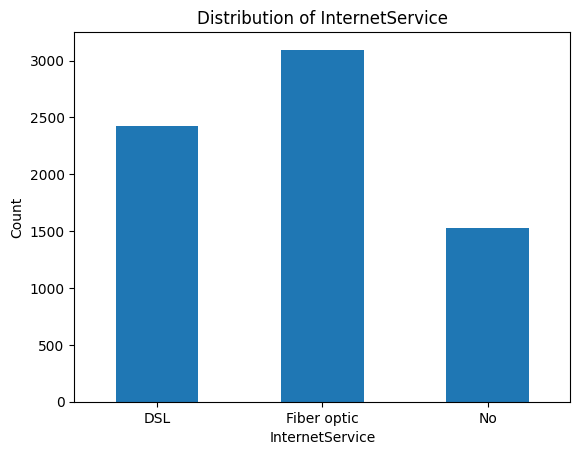

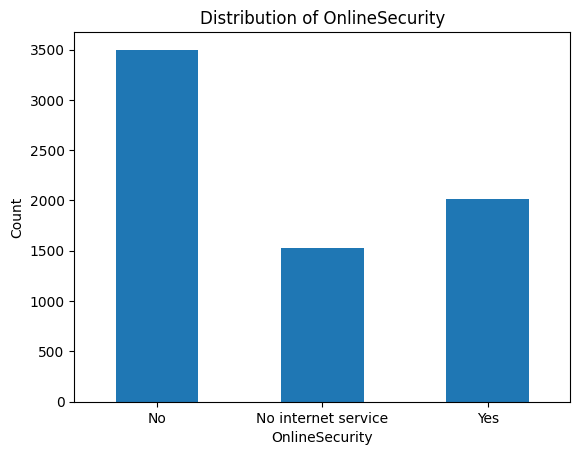

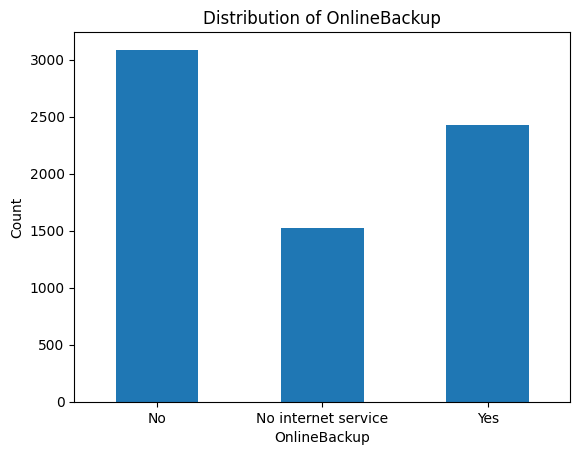

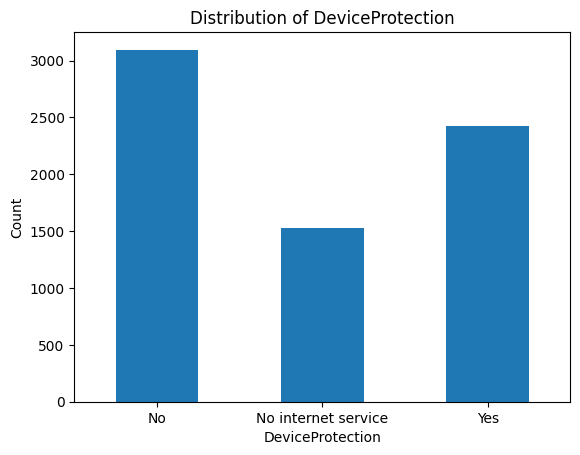

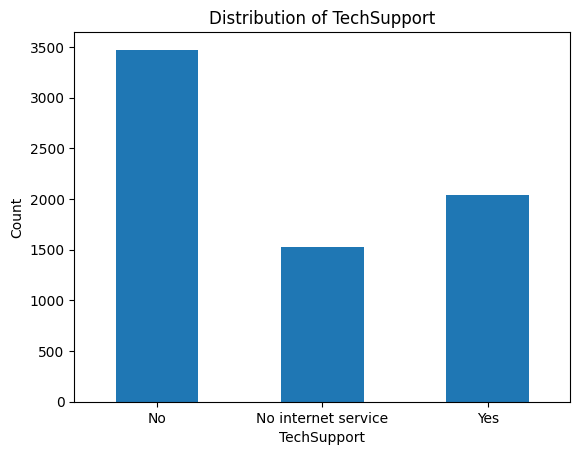

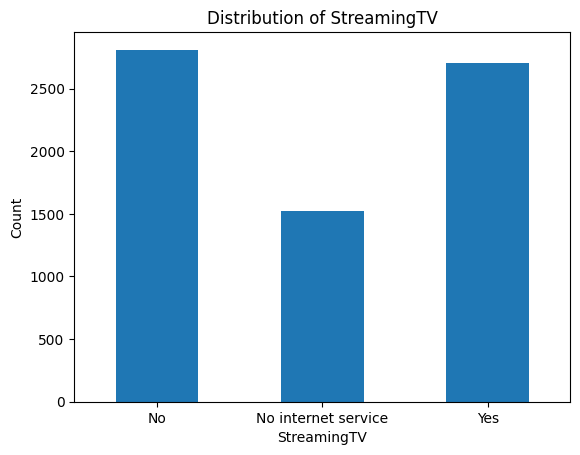

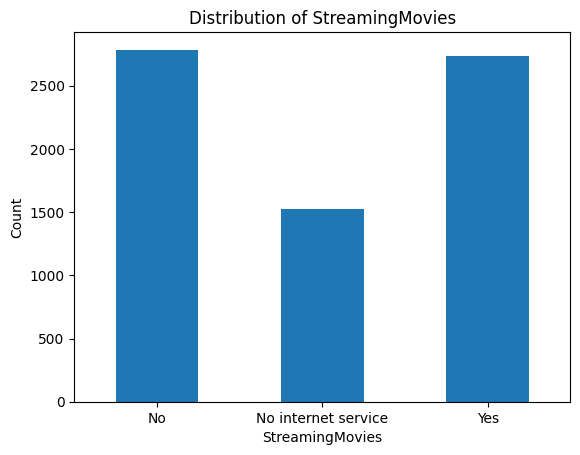

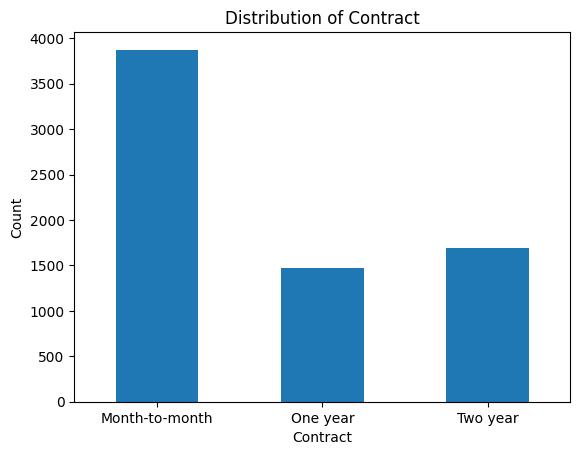

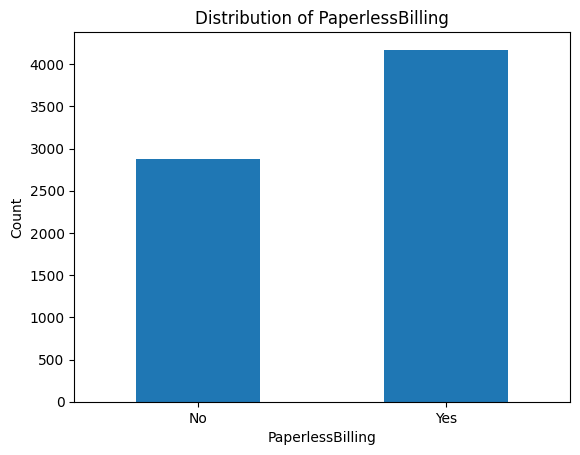

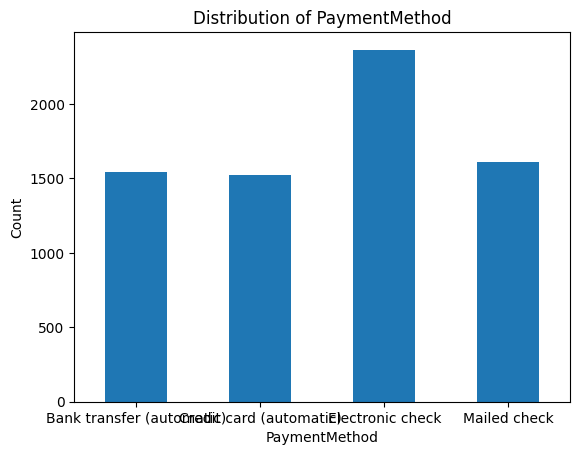

In [ ]:
# Bar plots for categorical features
for col in categorical_data.columns:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col, ylabel='Count')
    plt.savefig(f'{col}_distribution.png')
    plt.show()

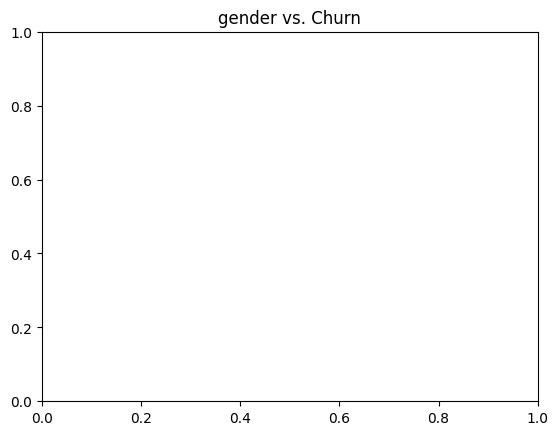

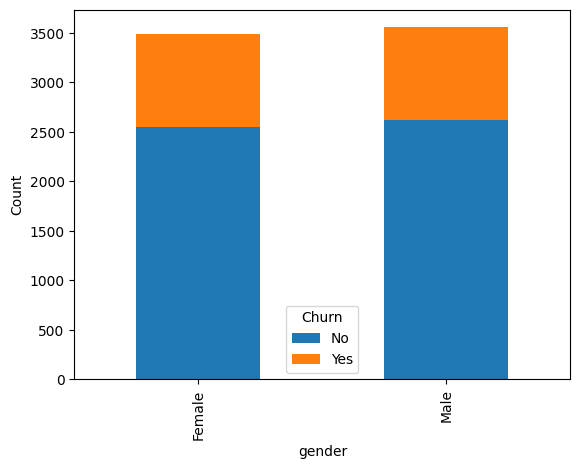

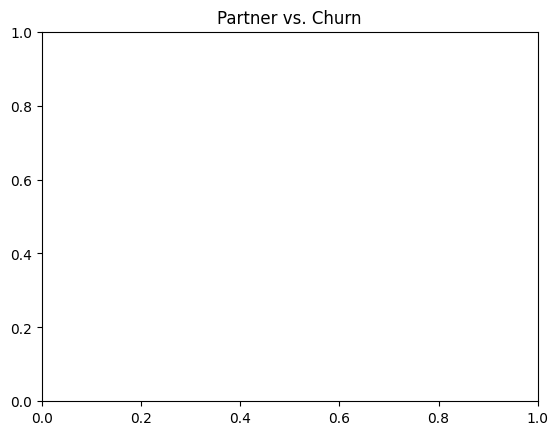

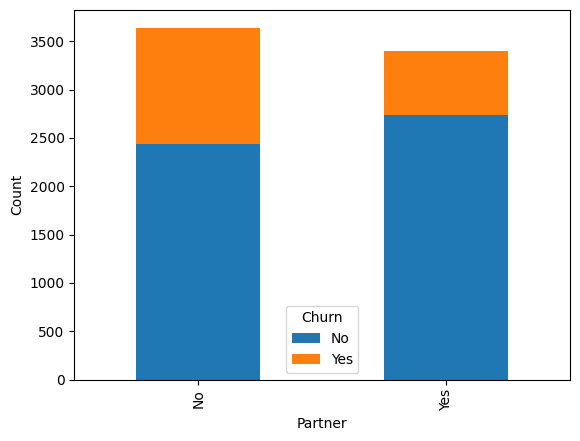

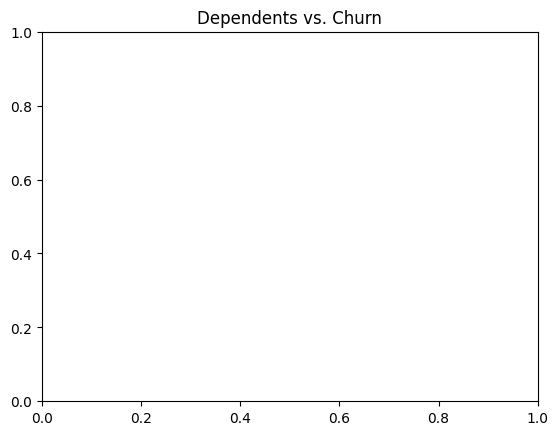

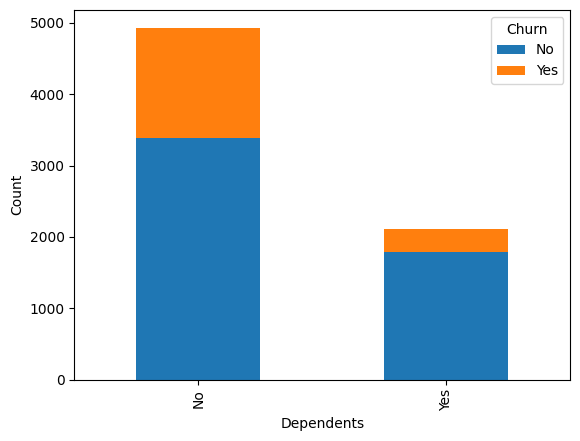

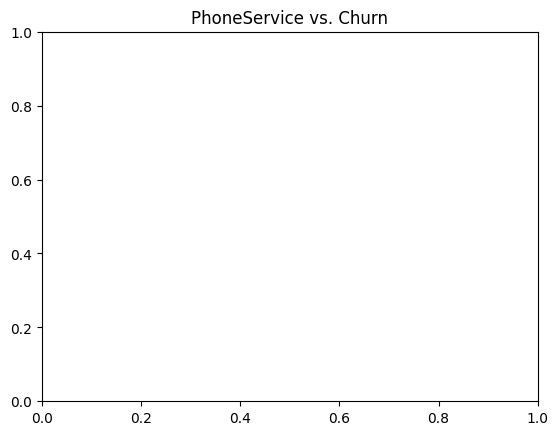

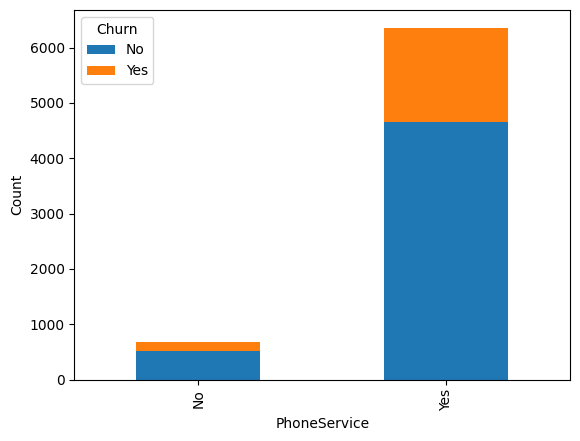

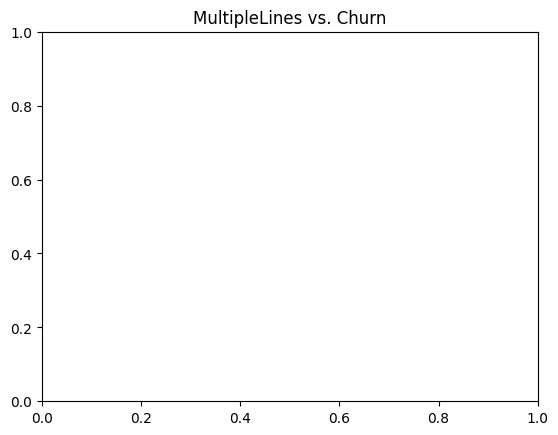

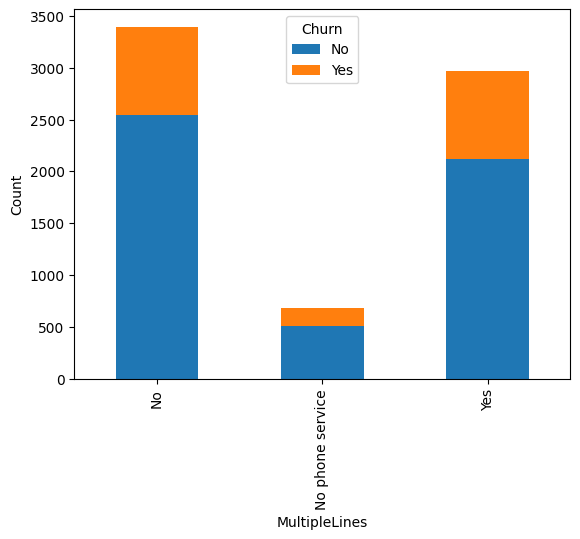

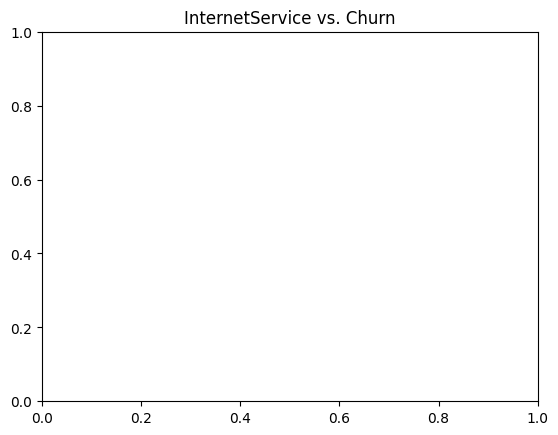

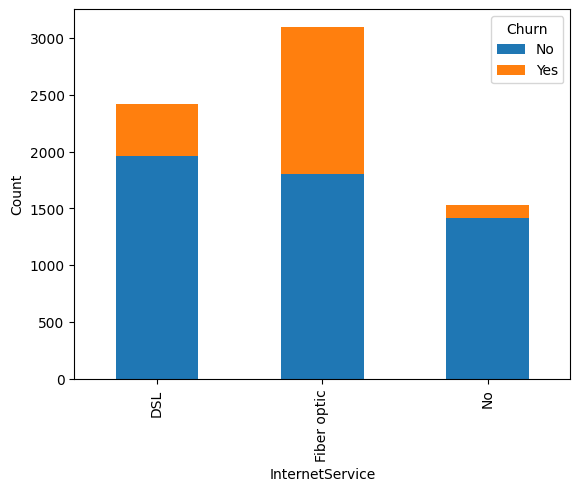

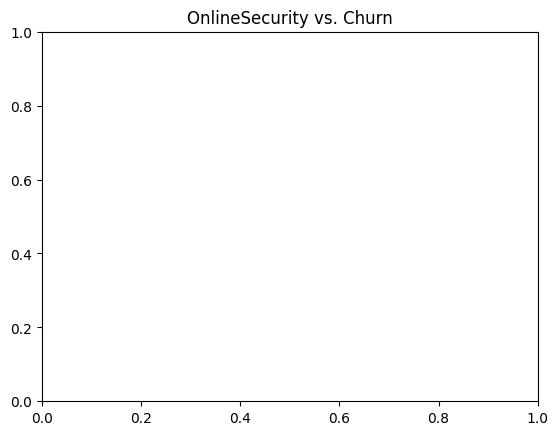

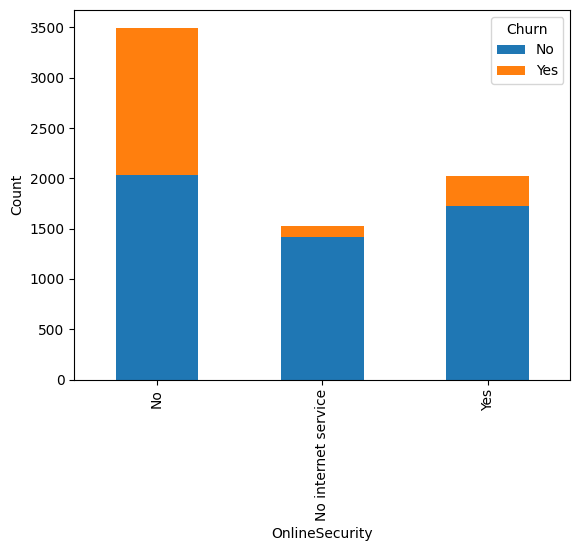

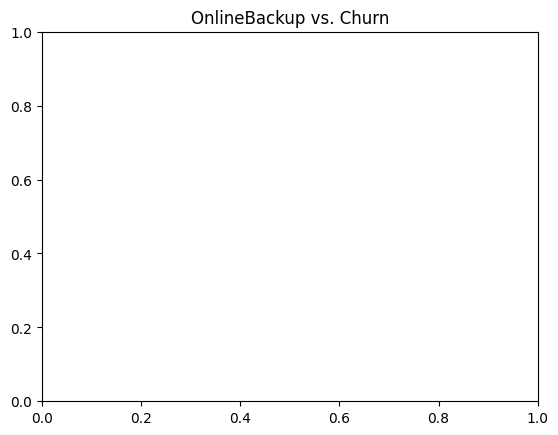

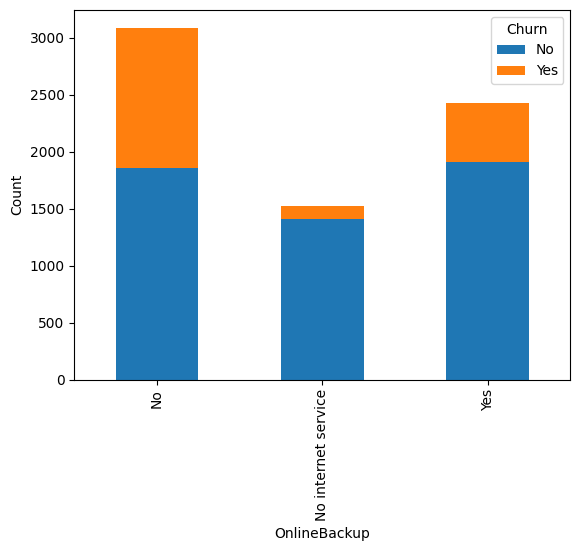

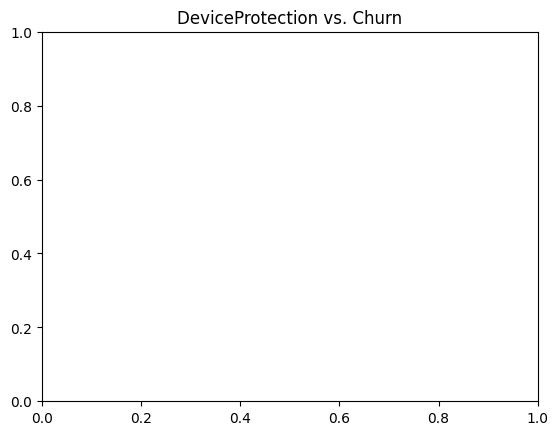

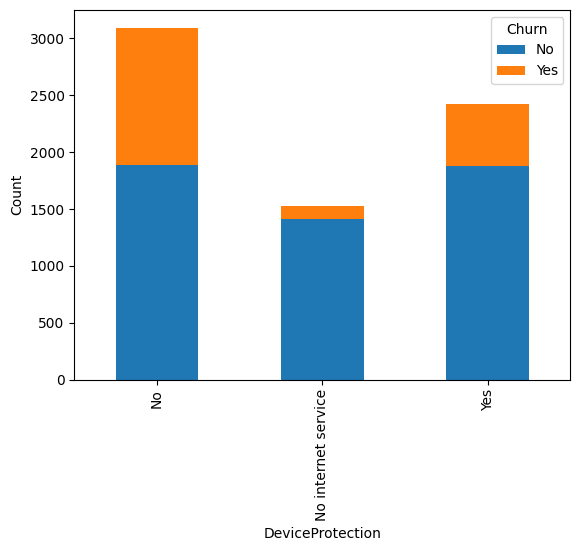

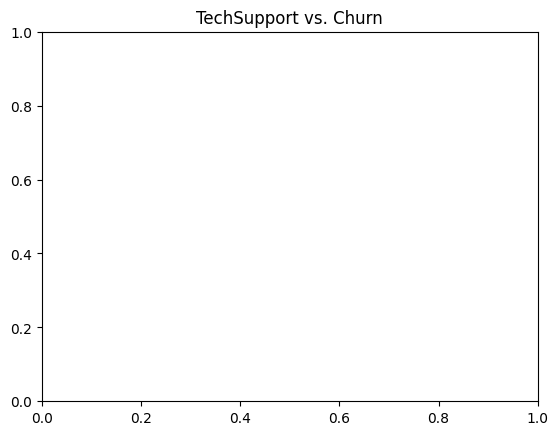

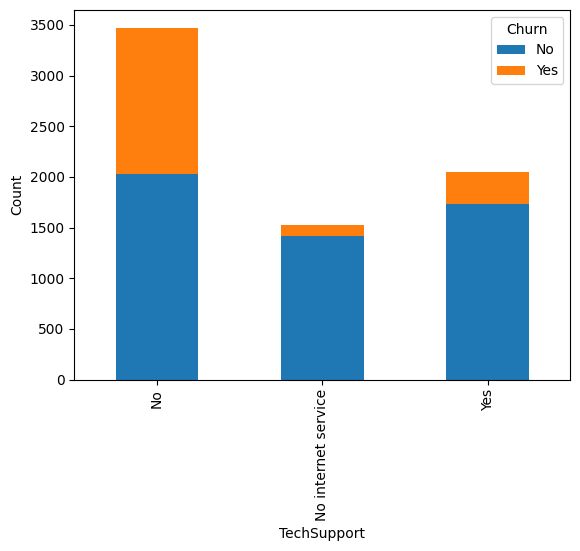

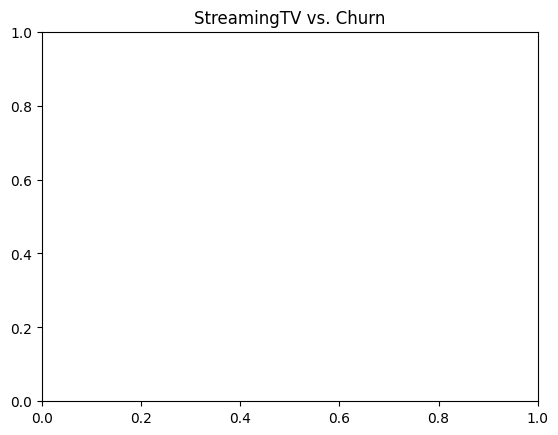

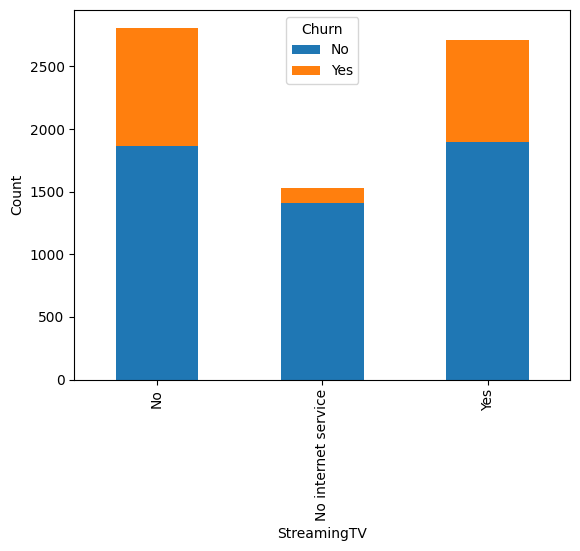

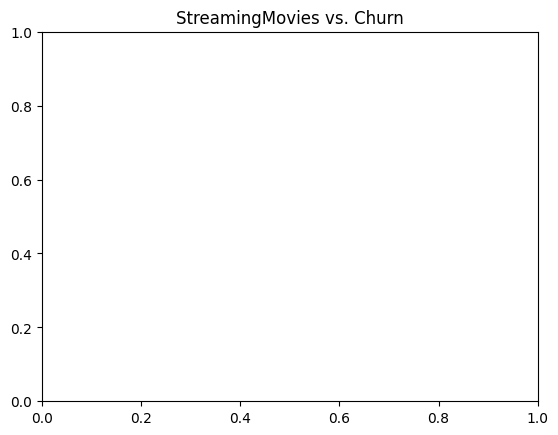

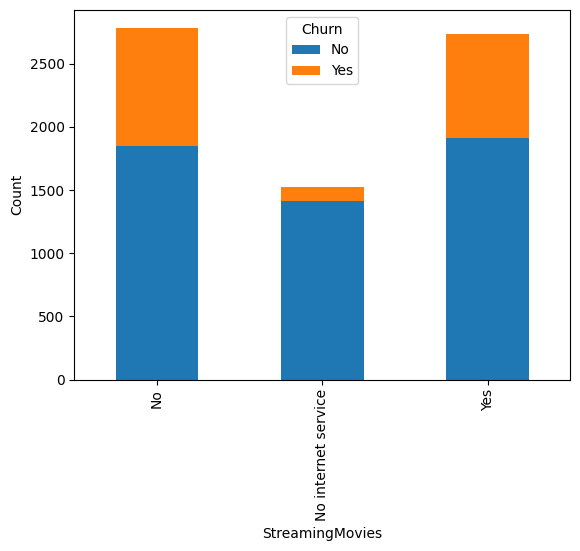

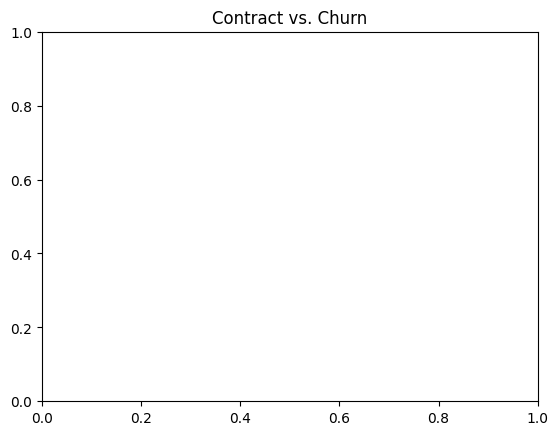

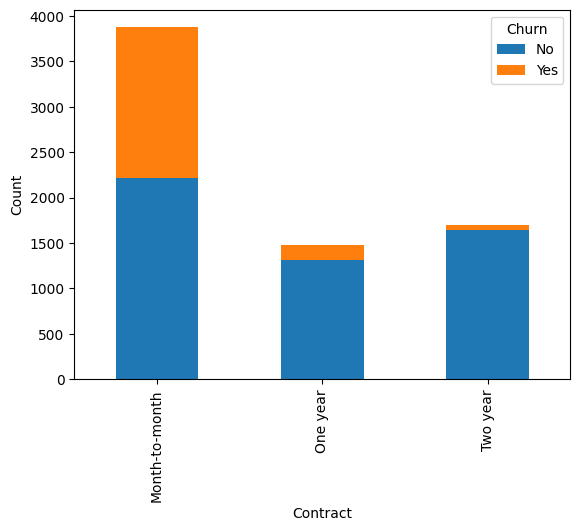

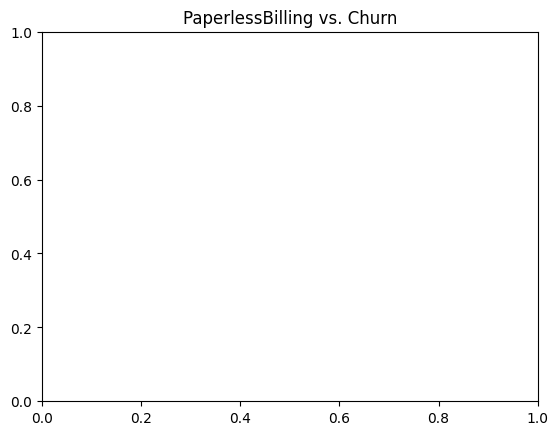

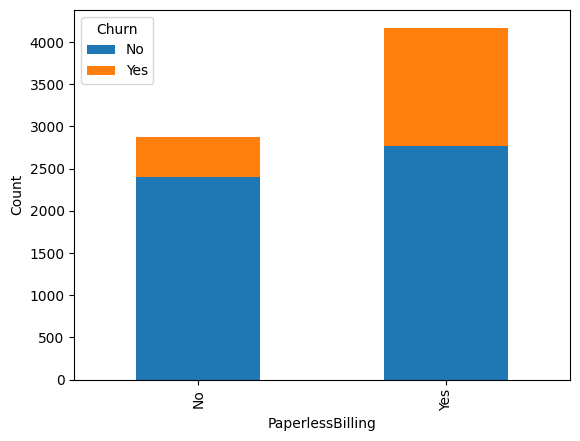

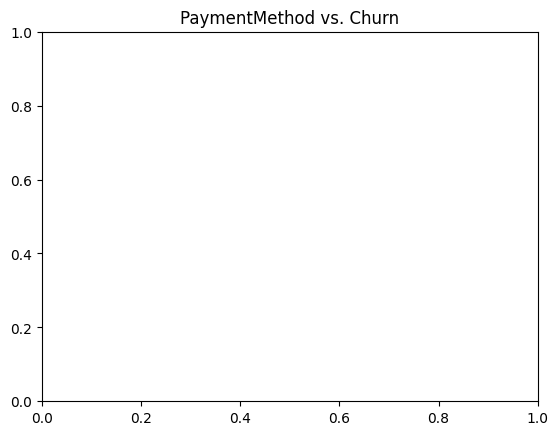

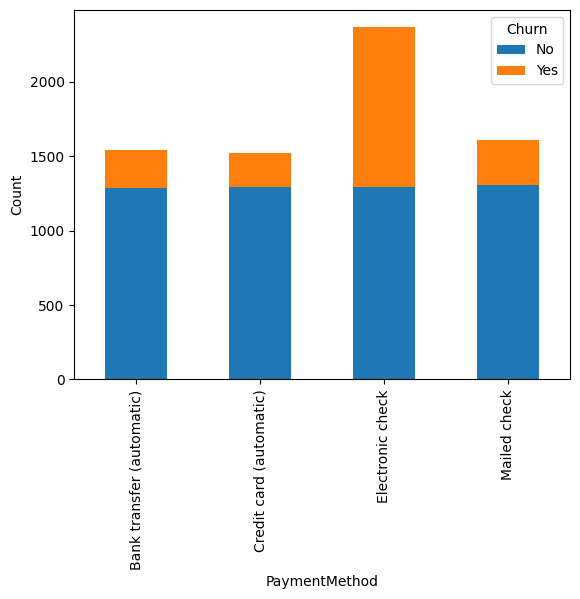

In [ ]:
for col in categorical_data.columns:

    plt.title(f'{col} vs. Churn')
    pd.crosstab(df[col], df['Churn']).plot(kind='bar', stacked=True)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.savefig(f'{col}_vs_churn.png')
    plt.show()
    print()

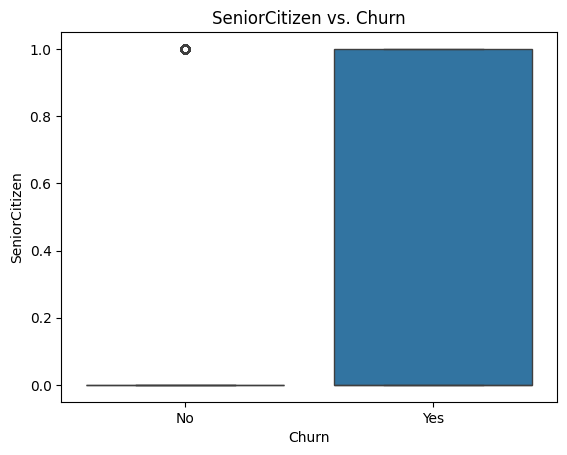

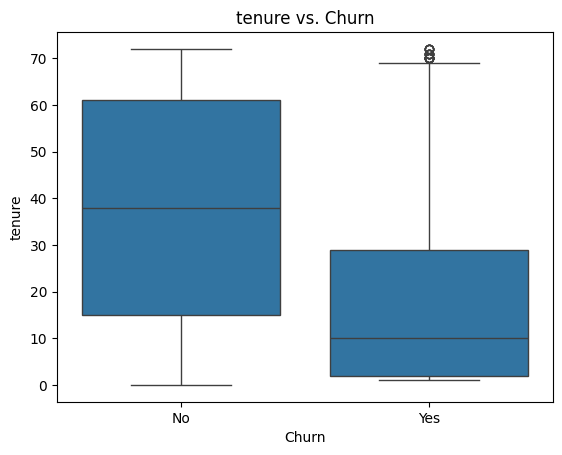

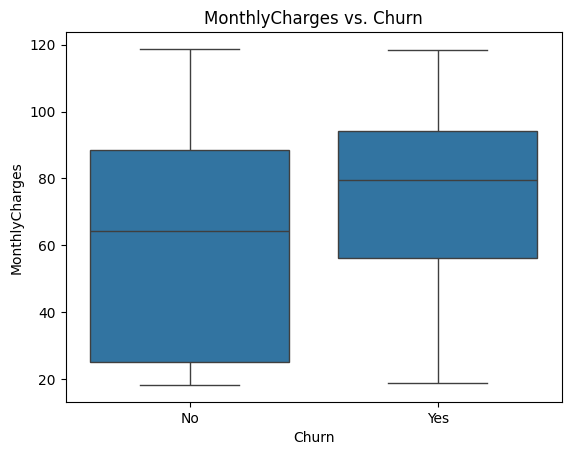

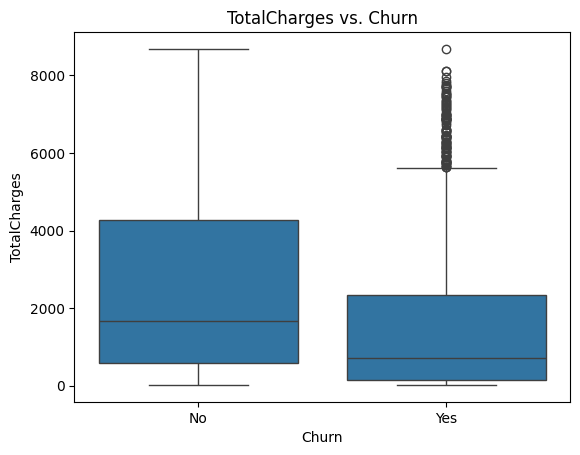

In [ ]:
for col in numerical_data.columns:
    plt.title(f'{col} vs. Churn')
    sns.boxplot(x='Churn', y=col, data=df)
    plt.savefig(f'{col}_vs_churn.png')
    plt.show()
    print()

# **Dataset pre-processing**

In [ ]:

print("\nEmpty or whitespace rows in object-type columns:")
object_columns = df.select_dtypes(include='object').columns
empty_counts = {}
for col in object_columns:
    empty_count = (df[col].str.strip() == '').sum()
    if empty_count > 0:
        empty_counts[col] = empty_count

if empty_counts:
    for col, count in empty_counts.items():
        print(f"Column '{col}' has {count} empty or whitespace rows")
else:
    print("No empty or whitespace rows found in any object-type column")

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)




Empty or whitespace rows in object-type columns:
No empty or whitespace rows found in any object-type column


In [ ]:
df_encoded = pd.get_dummies(df.drop('customerID', axis=1), drop_first=True)
print("Encoded columns:", df_encoded.columns.tolist())

Encoded columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'Churn_Yes']


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df_encoded[numerical_cols] = scaler.fit_transform(df_encoded[numerical_cols])
print("Scaled numerical features (first 5 rows):\n", df_encoded[numerical_cols].head())

Scaled numerical features (first 5 rows):
      tenure  MonthlyCharges  TotalCharges
0 -1.277445       -1.160323     -0.994242
1  0.066327       -0.259629     -0.173244
2 -1.236724       -0.362660     -0.959674
3  0.514251       -0.746535     -0.194766
4 -1.236724        0.197365     -0.940470


# **Dataset splitting**

In [ ]:
from sklearn.model_selection import train_test_split
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


df_encoded = pd.get_dummies(df.drop('customerID', axis=1), drop_first=True)
X = df_encoded.drop('Churn_Yes', axis=1)
y = df_encoded['Churn_Yes']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, random_state=42, stratify=y_temp)
print("Train set size:", len(X_train))
print("Test set size:", len(X_test))

Train set size: 4929
Test set size: 1409


# **Model training and testing (supervised)**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [ ]:

nn = MLPClassifier(hidden_layer_sizes=(100,50,25), activation='relu', solver='adam', max_iter=500,learning_rate_init=0.01,random_state=42,
                  )
nn.fit(X_train, y_train)
nn_pred = nn.predict(X_test)

nn.fit(X_train, y_train)
nn_pred = nn.predict(X_test)


# **Model training and testing (unsupervised)**

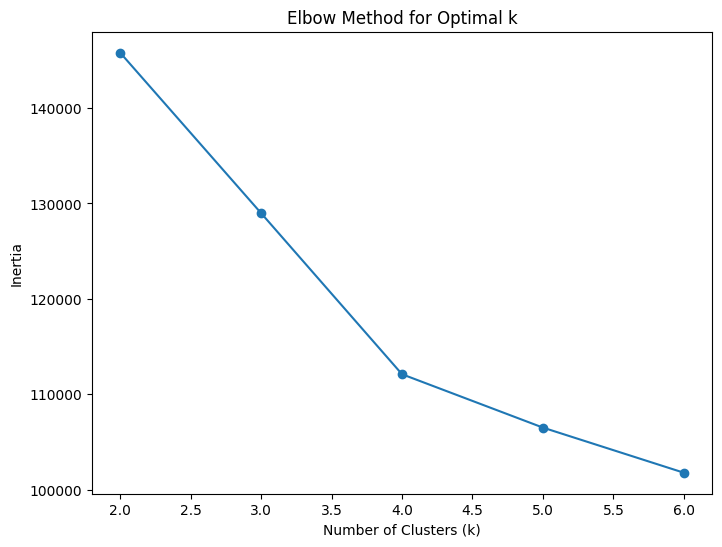

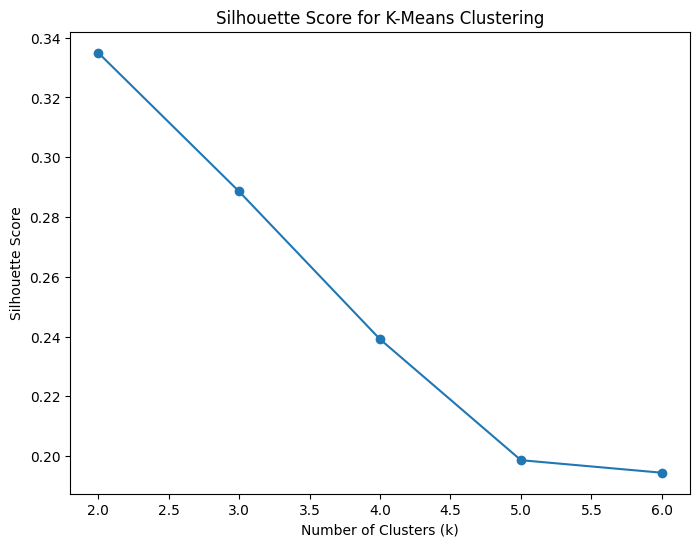

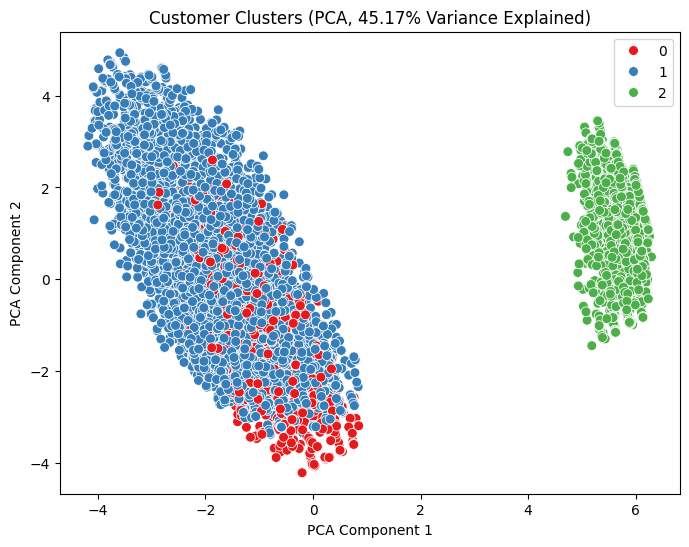


Cluster Characteristics (Mean Values):
            tenure  MonthlyCharges  TotalCharges  SeniorCitizen  \
Cluster                                                           
0        31.737537       42.028592   1500.131818       0.152493   
1        33.036194       81.755171   2901.536975       0.203930   
2        30.547182       21.079194    668.099443       0.034076   

         Contract_One year  Contract_Two year  InternetService_Fiber optic  \
Cluster                                                                      
0                 0.212610           0.236070                     0.000000   
1                 0.199380           0.185315                     0.640331   
2                 0.238532           0.418087                     0.000000   

         PaperlessBilling_Yes  
Cluster                        
0                    0.567449  
1                    0.690383  
2                    0.292267  

Cluster Sizes:
Cluster
0    0.096834
1    0.686497
2    0.216669
Name: p

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


df_encoded = pd.get_dummies(df.drop('customerID', axis=1), drop_first=True)
X = df_encoded.drop('Churn_Yes', axis=1)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


inertia = []
silhouette_scores = []
k_range = range(2, 7)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))


plt.figure(figsize=(8, 6))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.savefig('elbow_curve.png')
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(k_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for K-Means Clustering')
plt.savefig('silhouette_score.png')
plt.show()

optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)


df_encoded['Cluster'] = cluster_labels


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_.sum()


plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='Set1', s=50)
plt.title(f'Customer Clusters (PCA, {explained_variance:.2%} Variance Explained)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.savefig('cluster_visualization.png')
plt.show()


print("\nCluster Characteristics (Mean Values):")
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
key_categorical = ['Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic', 'PaperlessBilling_Yes']
cluster_summary = df_encoded.groupby('Cluster')[numerical_cols + key_categorical].mean()
print(cluster_summary)


print("\nCluster Sizes:")
print(df_encoded['Cluster'].value_counts(normalize=True).sort_index())

# **Model selction/Comparison analysis**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [ ]:
models = {'KNN': knn_pred, 'Logistic Regression': lr_pred, 'Neural Network': nn_pred}
metrics = {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-Score': [], 'AUC': []}
for name, pred in models.items():
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred))
    metrics['Recall'].append(recall_score(y_test, pred))
    metrics['F1-Score'].append(f1_score(y_test, pred))
    metrics['AUC'].append(roc_auc_score(y_test, pred))

print("Model Metrics:")
for metric, values in metrics.items():
    for model, value in zip(models.keys(), values):
        print(f"{model} {metric}: {value:.2f}")

Model Metrics:
KNN Accuracy: 0.77
Logistic Regression Accuracy: 0.81
Neural Network Accuracy: 0.80
KNN Precision: 0.57
Logistic Regression Precision: 0.66
Neural Network Precision: 0.68
KNN Recall: 0.44
Logistic Regression Recall: 0.56
Neural Network Recall: 0.45
KNN F1-Score: 0.50
Logistic Regression F1-Score: 0.60
Neural Network F1-Score: 0.54
KNN AUC: 0.66
Logistic Regression AUC: 0.73
Neural Network AUC: 0.69


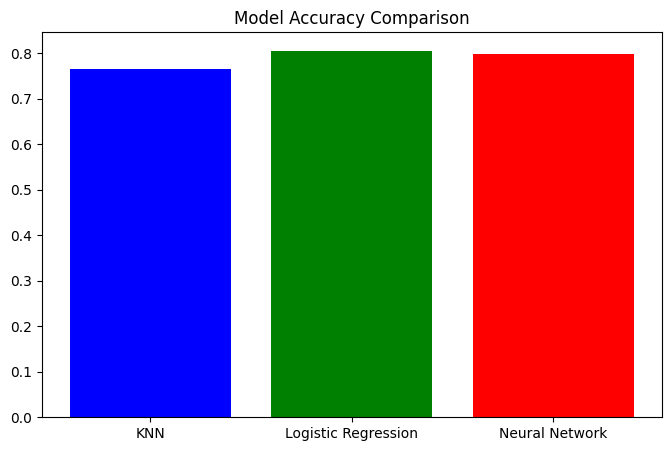

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(models.keys(), metrics['Accuracy'], color=['blue', 'green', 'red'])
plt.title('Model Accuracy Comparison')
plt.savefig('accuracy_comparison.png')
plt.show()

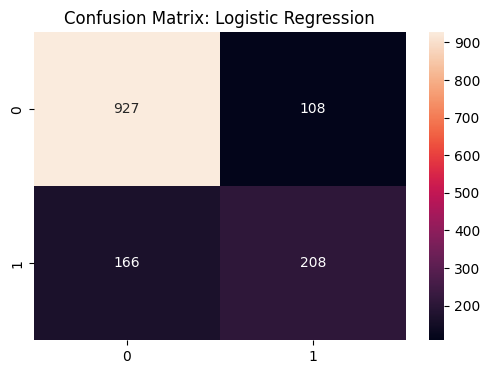

In [ ]:
cm_lr = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d')
plt.title('Confusion Matrix: Logistic Regression')
plt.savefig('cm_logistic.png')
plt.show()


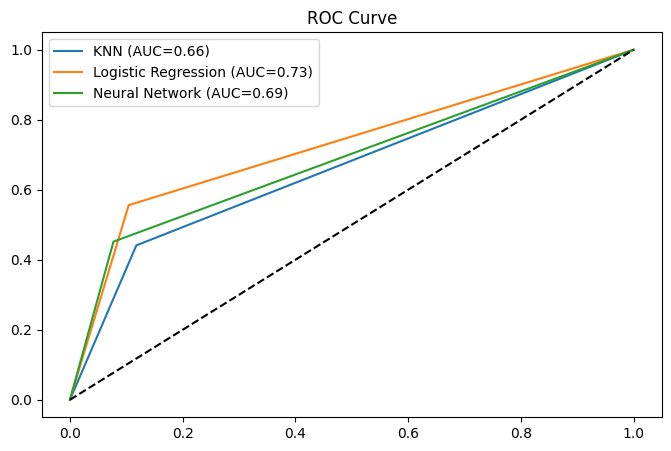

In [ ]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(8, 5))
for name, pred in models.items():
    fpr, tpr, _ = roc_curve(y_test, pred)
    plt.plot(fpr, tpr, label=f'{name} (AUC={metrics["AUC"][list(models.keys()).index(name)]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve')
plt.legend()
plt.savefig('roc_curve.png')
plt.show()